In [1]:
import pandas as pd
import numpy as np

btc = pd.read_csv("../data_clean/btc_clean.csv", index_col="date", parse_dates=True)
r = btc.loc["2018":"2025", "ret"]

In [2]:
wealth = (1 + r).cumprod()                      # growth of 1 USD, compounding
dd = wealth / wealth.cummax() - 1               # drawdown: distance below the highest point so far
q = r.quantile(0.05)                            # VaR 95%: the cut-off for the worst 5% of days

stats = {
    "annual vol": r.std() * np.sqrt(365),
    "CAGR": wealth.iloc[-1] ** (365 / len(r)) - 1,
    "max drawdown": dd.min(),
    "VaR 95%": -q,
    "CVaR 95%": -r[r <= q].mean(),              # average of the worst 5% of days
    "skew": r.skew(),
    "excess kurtosis": r.kurt(),
}
pd.Series(stats).round(4)

annual vol         0.6533
CAGR               0.2582
max drawdown      -0.8138
VaR 95%            0.0522
CVaR 95%           0.0793
skew              -0.2851
excess kurtosis    8.1945
dtype: float64

<Axes: title={'center': '30-day volatility, annualised'}, xlabel='date'>

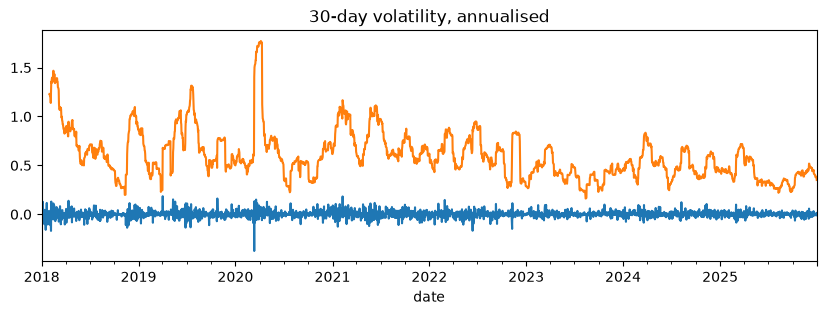

In [3]:
r.plot(title="BTC daily returns", figsize=(10, 3))

(r.rolling(30).std() * np.sqrt(365)).plot(title="30-day volatility, annualised", figsize=(10, 3))

In [4]:
rf = pd.read_csv("../data_raw/dtb3.csv", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
rf = rf.reindex(pd.date_range("2017-09-01", "2025-12-31")).ffill().shift(1) / 100
rf_daily = (1 + rf) ** (1 / 365) - 1
print(rf.loc["2018":"2025"].mean())
rf_daily.rename("rf").to_csv("../data_clean/rf_daily.csv")

0.025631074606433952
